In [6]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from clean_mission1 import OUT_DIR, load_cleaned
from label_mission1 import HORIZONS, MAIN_CLASSES, WINDOW, folds, load_events, load_labels

labels = load_labels()
events = pd.read_csv(f'{OUT_DIR}/events.csv', index_col='ID', parse_dates=['onset', 'end'])
anomalies = events[events.Category == 'Anomaly']
print(f'{len(labels):,} times, {labels.valid.mean():.1%} valid')
print({f'{h} min': int((labels.valid & labels[f'y_{h}']).sum()) for h in HORIZONS})

14,728,320 times, 89.2% valid
{'5 min': 1090, '15 min': 3270, '30 min': 6540}


In [7]:
# Brute-force check of labels and validity at random times, straight from the event table
raw = load_events()
onsets = raw[raw.Category == 'Anomaly'].onset
sample = labels.sample(20000, random_state=0)
for t, r in sample.iterrows():
    for h in HORIZONS:
        assert r[f'y_{h}'] == ((onsets > t) & (onsets <= t + pd.Timedelta(minutes=h))).any(), (t, h)
    if r.valid:
        assert not ((raw.onset <= t) & (raw.end >= t - WINDOW)).any(), t
assert (labels.minutes_to_onset[labels.y_30] > 0).all()  # positives always end before onset
print('labels and validity match the event table')

labels and validity match the event table


In [8]:
# Anomalies with no valid positive window: they start inside, or within WINDOW after, another event
anomalies[anomalies.valid_pos_30.isna() | (anomalies.valid_pos_30 == 0)][['Class', 'onset', 'end']]

,Class,onset,end
ID,,,
id_144,class_22,2000-02-12 19:25:48.966,2000-02-12 19:34:39.963
id_7,class_7,2002-07-20 17:27:15.534,2002-07-20 20:37:45.534
id_12,class_11,2003-12-30 20:31:55.191,2004-01-08 12:00:00.000
id_113,class_7,2006-11-28 00:11:39.336,2006-11-28 04:14:39.336
id_146,class_7,2010-05-23 21:18:00.153,2010-05-24 12:52:30.153
id_172,class_3,2012-09-19 13:42:51.000,2012-09-19 13:43:09.000
id_42,class_1,2012-12-06 18:34:09.723,2012-12-06 18:34:09.723
id_179,class_7,2013-07-23 21:25:29.964,2013-07-24 02:59:59.964
id_181,class_7,2013-08-27 17:26:59.961,2013-08-30 01:02:59.961


In [9]:
# Folds: train -> calibration year -> test, each separated by WINDOW + max horizon. Count usable anomalies.
usable = anomalies[anomalies.valid_pos_30 > 0]
gap = WINDOW + pd.Timedelta(minutes=max(HORIZONS))
rows = []
for f in folds():
    assert f['train'][1] + gap <= f['calib'][0] and f['calib'][1] + gap <= f['test'][0]
    count = lambda p: int(usable.onset.between(*f[p]).sum())
    te = usable[usable.test_block == f['name']]
    rows.append({'fold': f['name'], 'train_anomalies': count('train'), 'calib_anomalies': count('calib'),
                 'test_anomalies': len(te), **{c: int((te.Class == c).sum()) for c in MAIN_CLASSES}})
summary = pd.DataFrame(rows).set_index('fold')
print('pooled test:', summary[['test_anomalies', *MAIN_CLASSES]].sum().to_dict())
summary

pooled test: {'test_anomalies': 57, 'class_7': 23, 'class_3': 24}


,train_anomalies,calib_anomalies,test_anomalies,class_7,class_3
fold,,,,,
test_2006_2007,47,5,15,6,8
test_2008_2009,59,8,13,5,3
test_2010_2011,75,5,16,7,6
test_2012_2013,88,8,13,5,7


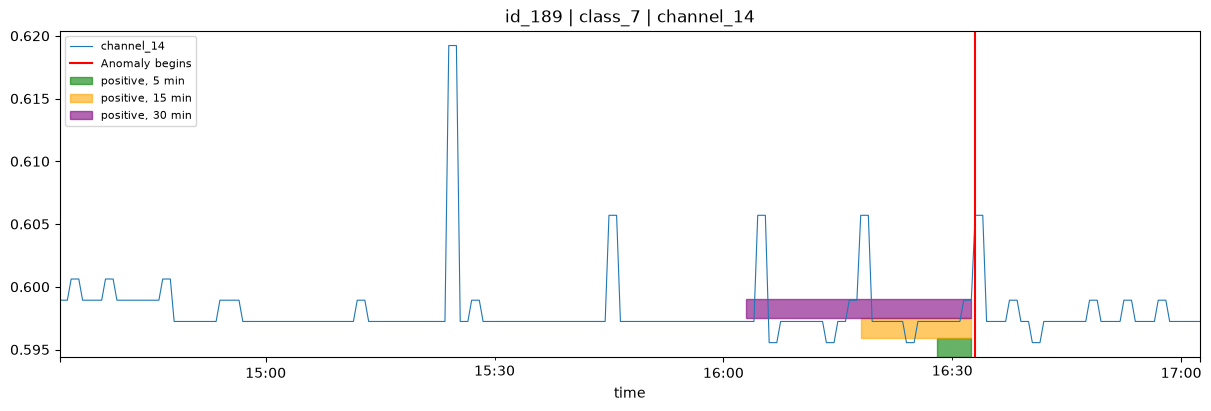

In [10]:
# Example: one class_7 anomaly with its valid positive times for each horizon
a = usable[usable.Class == 'class_7'].iloc[-1]
span = (a.onset - 2 * WINDOW, a.onset + pd.Timedelta(minutes=30))
x = load_cleaned(*span, channels=['channel_14'])['channel_14']
lab = labels.loc[span[0]:span[1]]

fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
x.plot(ax=ax, lw=0.8)
ax.axvline(a.onset, color='red', label='Anomaly begins')
for i, (h, c) in enumerate(zip(HORIZONS, ['green', 'orange', 'purple'])):
    pos = lab.index[lab.valid & lab[f'y_{h}']]
    ax.axvspan(pos.min(), pos.max(), ymin=0.06 * i, ymax=0.06 * (i + 1), color=c, alpha=0.6,
               label=f'positive, {h} min')
ax.legend(loc='upper left', fontsize=8)
ax.set_title(f'{a.name} | {a.Class} | channel_14')
plt.show()